# YouTube trending videos: views and engagement

## Summary

From November 14, 2017 to June 14, 2018, 161,470 YouTube trending records across the US, Canada, France, and GB show view counts from 223 to about 424.5 million. This notebook examines how views are associated with likes and comments among valid video-country records. It describes associations, not causes.

**Dependent variable:** `views` on the first recorded trending date.

**Comparison measures:** `likes` and `comment_count`. Category, tags, publishing time, and other factors are outside this notebook's scope.

## Problem statement

From November 14, 2017 to June 14, 2018, 161,470 YouTube Trending records from the US, Canada, France, and GB show views ranging from 223 to about 424.5 million. The relationship between views and likes or comments among valid video-country records is unclear, and unusable IDs or repeated rows can distort that comparison.

**Scope:** Views are the outcome; likes and comments are the comparison measures. This analysis describes associations, not causes.

## Table of contents

1. [Problem statement](#problem-statement)
2. [Part 1: Import libraries](#part-1-import-libraries)
3. [Part 2: View the data](#part-2-view-the-data)
4. [Part 3: Clean and prepare the data](#part-3-clean-and-prepare-the-data)
5. [Part 4: Further data cleaning](#part-4-further-data-cleaning)
6. [Part 5: Visualizations](#part-5-visualizations)
7. [Part 6: Findings and recommendations](#part-6-findings-and-recommendations)

## Part 1: Import libraries

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

## Part 2: View the data

Load the CSV, check its dimensions and column types, and preview a few records.

#### 1. Load the CSV file

In [24]:
youtube_df = pd.read_csv('data/youtube.csv')

#### 2. Check the number of rows and columns

In [25]:
youtube_df.shape

(161470, 18)

#### 3. Preview the first five rows

In [26]:
youtube_df.head(5)

,index,video_id,trending_date,title,channel_title,category_id,publish_date,time_frame,published_day_of_week,publish_country,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed
0,0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,13/11/2017,17:00 to 17:59,Monday,US,SHANtell martin,748374,57527,2966,15954,False,False,False
1,1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,13/11/2017,7:00 to 7:59,Monday,US,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,False,False,False
2,2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,12/11/2017,19:00 to 19:59,Sunday,US,"racist superman|""rudy""""|""""mancuso""""|""""king""""|""...",3191434,146033,5339,8181,False,False,False
3,3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,13/11/2017,11:00 to 11:59,Monday,US,"rhett and link|""gmm""""|""""good mythical morning""...",343168,10172,666,2146,False,False,False
4,4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,12/11/2017,18:00 to 18:59,Sunday,US,"ryan|""higa""""|""""higatv""""|""""nigahiga""""|""""i dare ...",2095731,132235,1989,17518,False,False,False


#### 4. Check the columns and data types

In [27]:
youtube_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 161470 entries, 0 to 161469
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   index                   161470 non-null  int64
 1   video_id                161470 non-null  str  
 2   trending_date           161470 non-null  str  
 3   title                   161470 non-null  str  
 4   channel_title           161470 non-null  str  
 5   category_id             161470 non-null  int64
 6   publish_date            161470 non-null  str  
 7   time_frame              161470 non-null  str  
 8   published_day_of_week   161470 non-null  str  
 9   publish_country         161470 non-null  str  
 10  tags                    161470 non-null  str  
 11  views                   161470 non-null  int64
 12  likes                   161470 non-null  int64
 13  dislikes                161470 non-null  int64
 14  comment_count           161470 non-null  int64
 15  comments_di

#### 5. View each column data type

In [28]:
youtube_df.dtypes

index                     int64
video_id                    str
trending_date               str
title                       str
channel_title               str
category_id               int64
publish_date                str
time_frame                  str
published_day_of_week       str
publish_country             str
tags                        str
views                     int64
likes                     int64
dislikes                  int64
comment_count             int64
comments_disabled          bool
ratings_disabled           bool
video_error_or_removed     bool
dtype: object

## Part 3: Clean and prepare the data

Check missing values, duplicates, unusable video IDs, and engagement-status flags. `#NAME?` is a placeholder ID, not a missing value. Use Missingno to view missingness.

#### 1. Count missing values in each column

In [29]:
youtube_df.isnull().sum()

index                     0
video_id                  0
trending_date             0
title                     0
channel_title             0
category_id               0
publish_date              0
time_frame                0
published_day_of_week     0
publish_country           0
tags                      0
views                     0
likes                     0
dislikes                  0
comment_count             0
comments_disabled         0
ratings_disabled          0
video_error_or_removed    0
dtype: int64

#### 2. Check the percentage of missing values

In [30]:
(youtube_df.isnull().mean() * 100).round(2)

index                     0.0
video_id                  0.0
trending_date             0.0
title                     0.0
channel_title             0.0
category_id               0.0
publish_date              0.0
time_frame                0.0
published_day_of_week     0.0
publish_country           0.0
tags                      0.0
views                     0.0
likes                     0.0
dislikes                  0.0
comment_count             0.0
comments_disabled         0.0
ratings_disabled          0.0
video_error_or_removed    0.0
dtype: float64

**Finding:** All columns have 0.00% missing values (0 of 161,470 rows), so no rows need to be dropped for nulls.

#### 3. Check duplicate rows

In [ ]:
duplicate_rows = youtube_df.drop(columns='index').duplicated()
print(f'Duplicate rows ignoring index: {duplicate_rows.sum():,} ({duplicate_rows.mean():.2%})')

**Finding and decision:** 219 rows (0.14%) repeat an existing row when the `index` column is ignored. Drop these exact repeats to avoid counting an observation twice. Two overlap with the invalid-ID rows, so do not add the percentages.

#### 4. Count unusable video IDs

In [ ]:
invalid_ids = youtube_df['video_id'] == '#NAME?'
print(f'Unusable video IDs: {invalid_ids.sum():,} ({invalid_ids.mean():.2%})')

**Finding and decision:** 1,799 rows (1.11%) use `#NAME?` instead of a video ID. Exclude them from video-level analysis because the video cannot be identified or reliably deduplicated. After exact duplicates and invalid IDs are removed, 2,016 rows (1.25%) are removed in total.

#### 5. Count rows with comments or ratings disabled

In [ ]:
print(f"Comments disabled: {youtube_df['comments_disabled'].sum():,} ({youtube_df['comments_disabled'].mean():.2%})")
print(f"Ratings disabled: {youtube_df['ratings_disabled'].sum():,} ({youtube_df['ratings_disabled'].mean():.2%})")
print(f"Video error or removed: {youtube_df['video_error_or_removed'].sum():,} ({youtube_df['video_error_or_removed'].mean():.2%})")

**Finding and decision:** Comments are disabled in 2,788 rows (1.73%) and ratings in 1,424 rows (0.88%). Keep these rows for views, but exclude them only from the matching comments or likes comparison. Another 141 rows (0.09%) are flagged as a video error or removal; report the flag, but do not automatically drop them because the captured counts are present and the flag alone does not prove they are missing.

#### 6. Visualize missing values

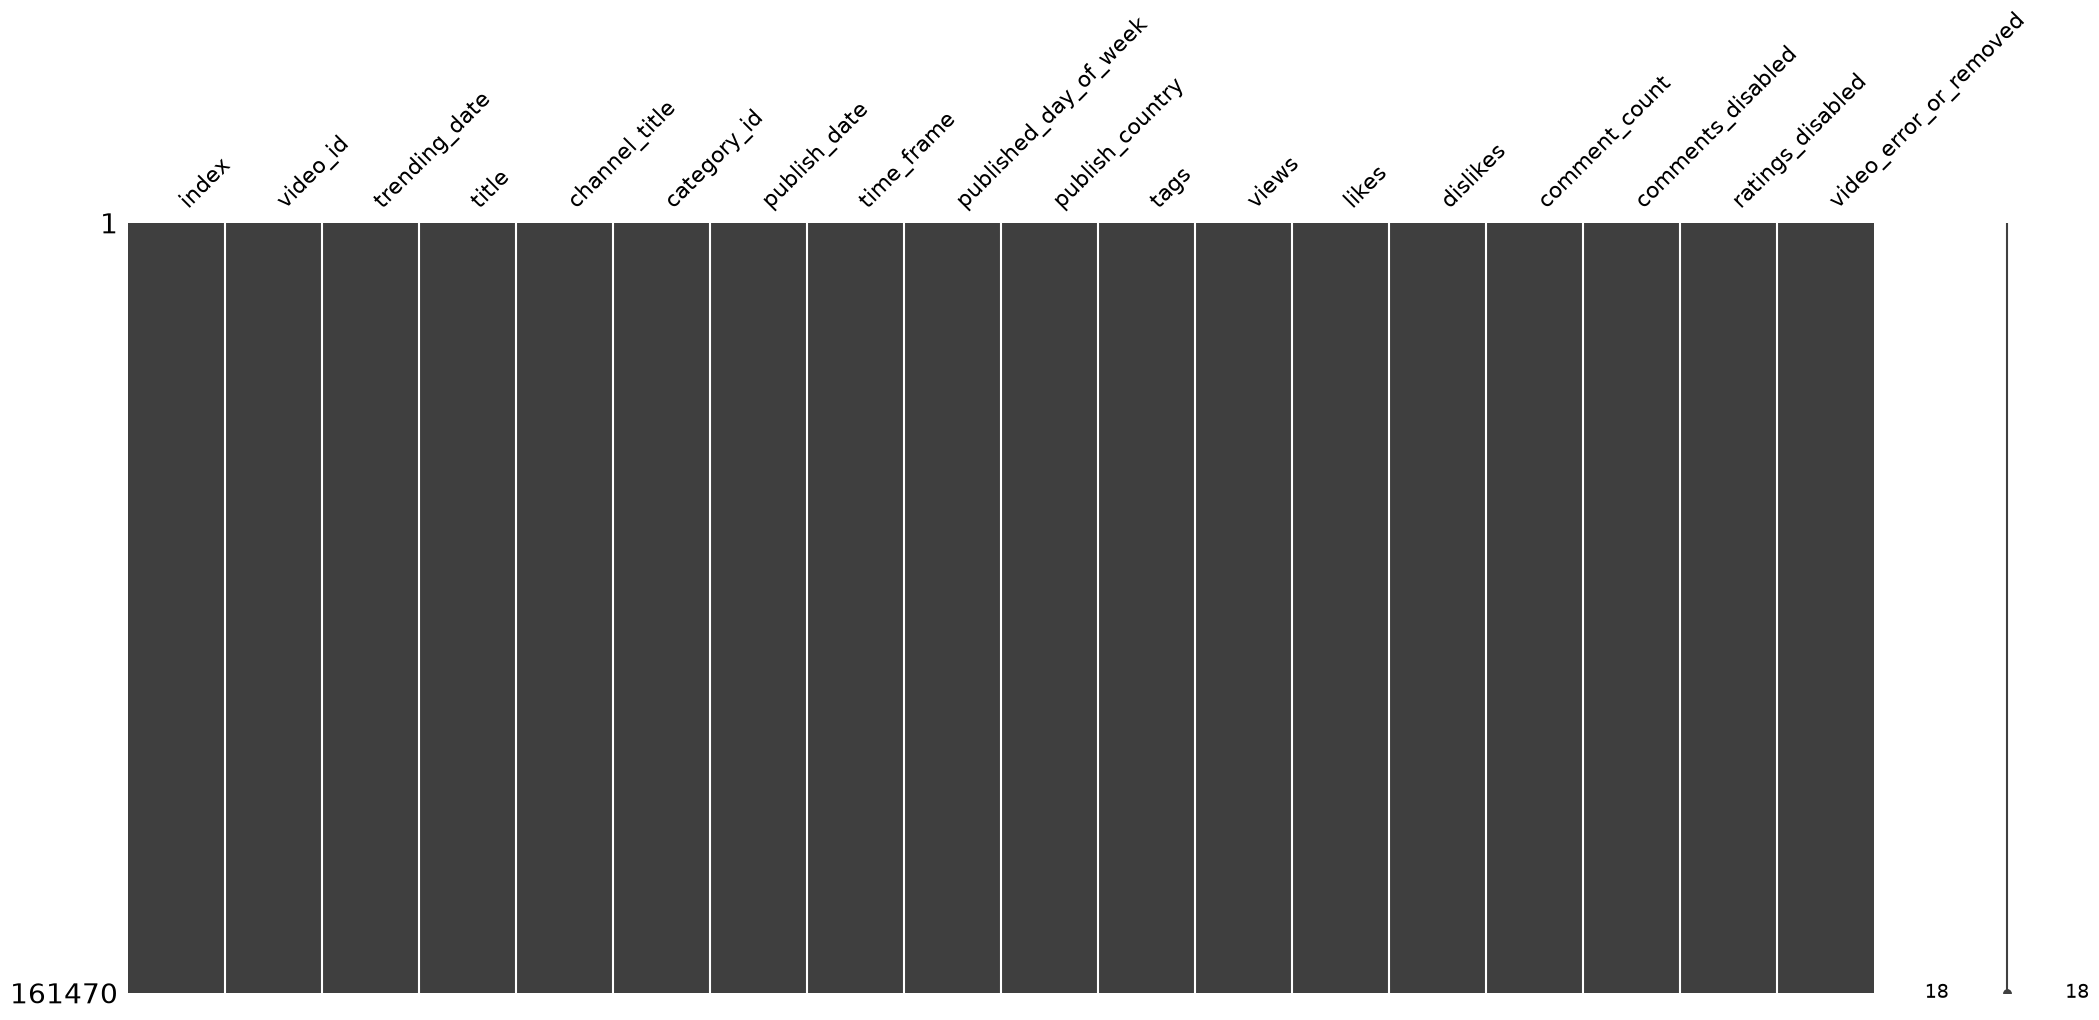

In [34]:
msno.matrix(youtube_df)
plt.show()

## Part 4: Further data cleaning

Create `newyoutube_df`, remove invalid IDs and repeated rows, convert the dates, and keep the first trending record for each video-country pair.

#### 1. Create a clean working dataframe and remove the row index

In [35]:
newyoutube_df = youtube_df.drop(columns='index').drop_duplicates().copy()
newyoutube_df.shape

(161251, 17)

#### 2. Remove rows with an unusable video ID

In [ ]:
newyoutube_df = newyoutube_df[newyoutube_df['video_id'] != '#NAME?'].copy()
rows_removed = len(youtube_df) - len(newyoutube_df)
print(f'Remaining after duplicate and ID cleaning: {len(newyoutube_df):,}')
print(f'Rows removed: {rows_removed:,} ({rows_removed / len(youtube_df):.2%})')

#### 3. Convert the date columns to datetime

In [37]:
newyoutube_df['trending_date'] = pd.to_datetime(newyoutube_df['trending_date'], format='%y.%d.%m')
newyoutube_df['publish_date'] = pd.to_datetime(newyoutube_df['publish_date'], format='%d/%m/%Y')
newyoutube_df[['trending_date', 'publish_date']].dtypes

trending_date    datetime64[us]
publish_date     datetime64[us]
dtype: object

#### 4. Keep the first trending record for each video in each country

In [38]:
newyoutube_df = newyoutube_df.sort_values('trending_date', kind='stable')
newyoutube_df = newyoutube_df.drop_duplicates(subset=['video_id', 'publish_country'], keep='first')
newyoutube_df.shape

(63801, 17)

#### 5. Prepare the likes and comments data

In [39]:
likes_df = newyoutube_df[newyoutube_df['ratings_disabled'] == False]
comments_df = newyoutube_df[newyoutube_df['comments_disabled'] == False]
print('Rows for likes:', len(likes_df))
print('Rows for comments:', len(comments_df))

Rows for likes: 63010
Rows for comments: 62587


## Part 5: Visualizations

Compare views with likes and comments using Spearman correlation and simple charts. Skip records where the corresponding feature is disabled. The log-scale scatterplots leave out zero counts.

#### 1. Check the relationship between views and likes

In [40]:
likes_df['views'].corr(likes_df['likes'], method='spearman')

np.float64(0.8297367920001746)

#### 2. Check the relationship between views and comments

In [41]:
comments_df['views'].corr(comments_df['comment_count'], method='spearman')

np.float64(0.800914685046412)

#### 3. Plot the distribution of views

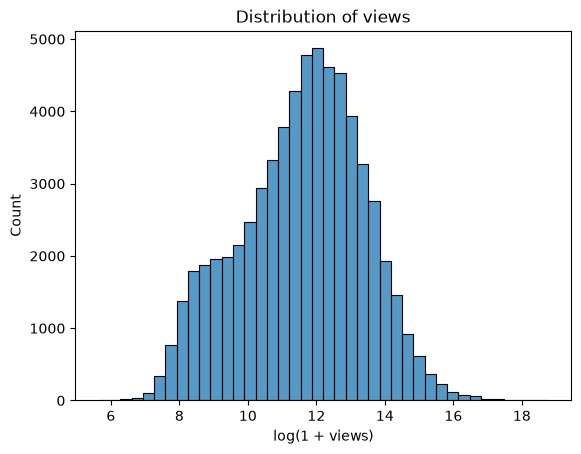

In [42]:
sns.histplot(np.log1p(newyoutube_df['views']), bins=40)
plt.title('Distribution of views')
plt.xlabel('log(1 + views)')
plt.show()

#### 4. Plot views and likes

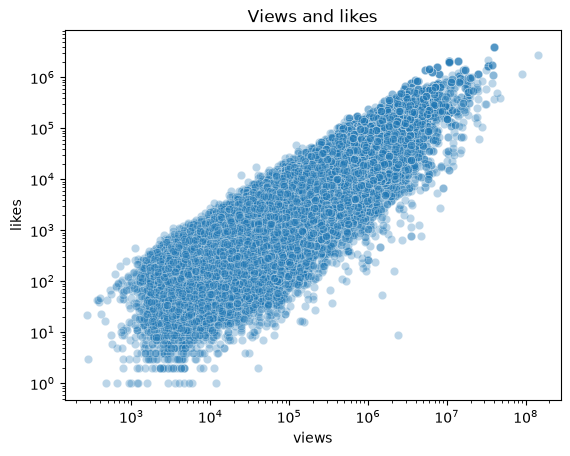

In [43]:
sns.scatterplot(data=likes_df[likes_df['likes'] > 0], x='views', y='likes', alpha=0.3)
plt.xscale('log')
plt.yscale('log')
plt.title('Views and likes')
plt.show()

#### 5. Plot views and comments

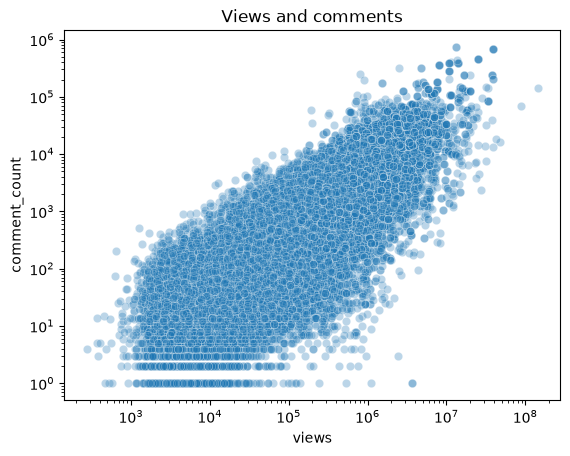

In [44]:
sns.scatterplot(data=comments_df[comments_df['comment_count'] > 0], x='views', y='comment_count', alpha=0.3)
plt.xscale('log')
plt.yscale('log')
plt.title('Views and comments')
plt.show()

## Part 6: Findings and recommendations

### Findings

- Views and likes: report the direction and strength of the observed association.
- Views and comments: report the direction and strength of the observed association.

### Limitations

Note invalid IDs, repeated records, disabled engagement fields, and why the results describe associations rather than causes.

### Recommendations

Suggest only next steps supported by the results. Do not claim that likes or comments cause views to increase.